# 03 · Auto-etiquetado de keypoints en frames propios (Bundesliga)

**Objetivo:** aplicar el modelo base de keypoints (entrenado con SoccerNet) sobre frames propios de la Bundesliga para generar anotaciones automáticas que, tras revisión manual, servirán para el fine-tuning.

**Contexto:** el modelo base alcanzó un Pose mAP50 de 0.95 sobre SoccerNet, pero esos son partidos con características de cámara distintas a los vídeos de la Bundesliga del proyecto. Para adaptar el modelo a este dominio concreto se aplicará fine-tuning con frames propios. Siguiendo la misma metodología de active learning usada en el detector, el modelo base pre-etiqueta y el revisor humano corrige.

**Entrada:** modelo `keypoints_base.pt` y frames de Bundesliga en `data/frames/`.

**Salida:** predicciones de keypoints sobre una selección de frames propios, listas para revisar.

In [1]:
from ultralytics import YOLO
from pathlib import Path
import random
import shutil

REPO_ROOT = Path("../..").resolve()
MODEL_PATH = REPO_ROOT / "models" / "keypoints_base.pt"
FRAMES_DIR = REPO_ROOT / "data" / "frames"
OUTPUT_DIR = REPO_ROOT / "data" / "keypoints_autolabel"

N_FRAMES = 120  # número de frames a seleccionar para el fine-tuning

model = YOLO(str(MODEL_PATH))
print(f"Modelo cargado: {MODEL_PATH.name}")
print(f"Keypoints del modelo: {model.model.kpt_shape}")

Modelo cargado: keypoints_base.pt
Keypoints del modelo: [24, 3]


## 1. Selección de frames variados

Se seleccionan frames de distintos vídeos para asegurar variedad de situaciones (distintas zonas del campo, ángulos de cámara). Se reparten equitativamente entre las subcarpetas de vídeo disponibles.

In [2]:
subdirs = [d for d in FRAMES_DIR.iterdir() if d.is_dir()]
print(f"Subcarpetas de vídeo: {len(subdirs)}")

# Repartir N_FRAMES entre los vídeos disponibles
frames_por_video = max(1, N_FRAMES // len(subdirs))
seleccionados = []

for d in subdirs:
    frames = list(d.glob("*.jpg"))
    n = min(frames_por_video, len(frames))
    seleccionados.extend(random.sample(frames, n))

# Ajustar al número exacto deseado
random.shuffle(seleccionados)
seleccionados = seleccionados[:N_FRAMES]

print(f"Frames seleccionados: {len(seleccionados)}")

Subcarpetas de vídeo: 12
Frames seleccionados: 120


## 2. Generación de predicciones en formato YOLO-pose

Se aplica el modelo a cada frame seleccionado y se guardan las imágenes junto con sus anotaciones de keypoints en formato YOLO-pose, listas para subir a Roboflow.

In [3]:
images_out = OUTPUT_DIR / "images"
labels_out = OUTPUT_DIR / "labels"
images_out.mkdir(parents=True, exist_ok=True)
labels_out.mkdir(parents=True, exist_ok=True)

CONF_MIN = 0.5
N_KEYPOINTS = 24
procesados = 0

for frame_path in seleccionados:
    res = model(str(frame_path), verbose=False, conf=0.25)
    r = res[0]

    if r.keypoints is None or len(r.boxes) == 0:
        continue

    # Tomar la primera detección (el campo)
    kps_xy = r.keypoints.xyn[0].cpu().numpy()      # normalizado
    kps_conf = r.keypoints.conf[0].cpu().numpy()

    # bbox normalizado del campo (cubre toda la imagen)
    partes = ["0", "0.5", "0.5", "1.0", "1.0"]
    for (x, y), c in zip(kps_xy, kps_conf):
        v = 2 if c > CONF_MIN else 0
        if v == 0:
            partes.extend(["0", "0", "0"])
        else:
            partes.extend([f"{x:.6f}", f"{y:.6f}", "2"])

    # Copiar imagen y guardar etiqueta
    nombre = f"{frame_path.parent.name}_{frame_path.name}".replace(" ", "_")
    shutil.copy2(frame_path, images_out / nombre)
    label_name = nombre.rsplit(".", 1)[0] + ".txt"
    with open(labels_out / label_name, "w") as f:
        f.write(" ".join(partes) + "\n")

    procesados += 1

print(f"Frames procesados y etiquetados: {procesados}")
print(f"Guardados en: {OUTPUT_DIR}")

Frames procesados y etiquetados: 120
Guardados en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\keypoints_autolabel


## 3. Verificación visual

Se visualizan algunas predicciones para comprobar la calidad antes de subirlas a revisar.

Figura guardada en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\keypoints_bundesliga_preview.png


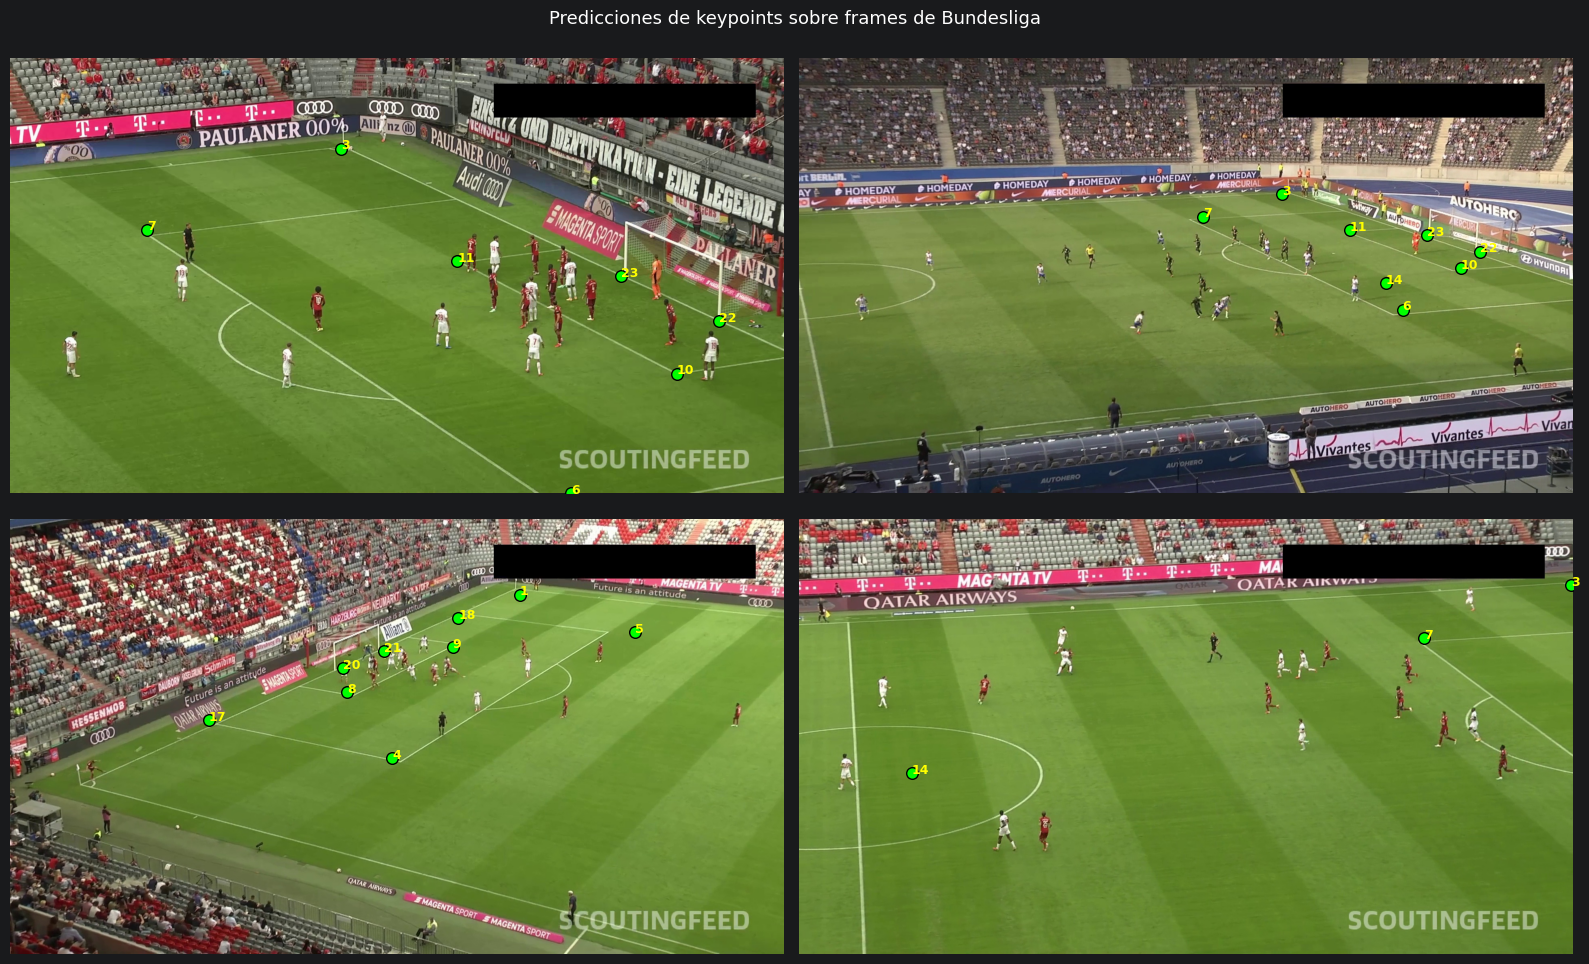

In [4]:
import matplotlib.pyplot as plt
import cv2

muestras = random.sample(list(images_out.glob("*.jpg")), min(4, procesados))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, img_path in zip(axes.flat, muestras):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    label_path = labels_out / (img_path.stem + ".txt")
    with open(label_path) as f:
        valores = f.read().split()
    kps = valores[5:]
    for i in range(N_KEYPOINTS):
        x, y, v = kps[i*3:i*3+3]
        if int(v) == 2:
            ax.scatter(float(x)*w, float(y)*h, c="lime", s=70, edgecolors="black", zorder=3)
            ax.annotate(str(i), (float(x)*w, float(y)*h), color="yellow", fontsize=9, fontweight="bold")

    ax.imshow(img)
    ax.axis("off")

plt.suptitle("Predicciones de keypoints sobre frames de Bundesliga", fontsize=13)
plt.tight_layout()
output_fig = REPO_ROOT / "outputs" / "keypoints_bundesliga_preview.png"
plt.savefig(str(output_fig), dpi=100, bbox_inches="tight")
print(f"Figura guardada en: {output_fig}")
plt.show()